# CS 521 HW4, Problem 1: Interval Bound Propagation (IBP) training

Brian Kim (bmkim2)

Network: 3 hidden layers of 50 neurons (Linear + ReLU), trained on MNIST with cross-entropy.
The data loaders and the box verifier come from HW2 Problem 4.

* (a) IBP training with $\kappa: 1 \to 0.5$ and $\epsilon_{train}: 0 \to 0.1$. Report the clean accuracy, the PGD accuracy and the training time, compared with standard training.
* (b) Verified accuracy with the HW2 box verifier for 10 values of $\epsilon_{test}$ in $[0.01, 0.1]$, plus adversarial examples where the network is not certified.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets, transforms

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

np.random.seed(42)
torch.manual_seed(42)
torch.set_num_threads(2)


device: cpu


## Data (HW2 loaders)

In [2]:
batch_size = 128

train_dataset = datasets.MNIST("data/", train=True, download=True, transform=transforms.ToTensor())
test_dataset = datasets.MNIST("data/", train=False, download=True, transform=transforms.ToTensor())

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=1000, shuffle=False)

## Network

No normalization layer, so the input box is directly $[x - \epsilon, x + \epsilon] \cap [0, 1]$ (this is also the network of Problem 2).

In [3]:
def make_model():
    return nn.Sequential(
        nn.Flatten(),
        nn.Linear(784, 50), nn.ReLU(),
        nn.Linear(50, 50), nn.ReLU(),
        nn.Linear(50, 50), nn.ReLU(),
        nn.Linear(50, 10),
    ).to(device)


def linear_layers(model):
    return [m for m in model if isinstance(m, nn.Linear)]

## Box verifier (HW2)

The HW2 `verify_batch`, changed only to walk through all the linear layers of this network. The last layer is merged with the specification $z_y - z_j$ (Equation 9 of the IBP paper).

In [4]:
def interval_affine(l, u, W, b):
    mu = (l + u) / 2.0
    r = (u - l) / 2.0
    center = mu @ W.t() + b
    rad = r @ W.t().abs()
    return center - rad, center + rad


@torch.no_grad()
def verify_batch(model, images, labels, eps):
    # Returns a boolean tensor (B,): True if the image is certified robust at radius eps.
    x = images.view(images.shape[0], -1)
    l, u = (x - eps).clamp(0.0, 1.0), (x + eps).clamp(0.0, 1.0)
    layers = linear_layers(model)
    for layer in layers[:-1]:
        l, u = interval_affine(l, u, layer.weight, layer.bias)
        l, u = l.clamp(min=0.0), u.clamp(min=0.0)

    I = torch.eye(10, device=images.device)
    M = I[labels].unsqueeze(1) - I.unsqueeze(0)          # (B,10,10): row j is e_y - e_j
    diff_W = M @ layers[-1].weight                        # (B,10,50)
    diff_b = M @ layers[-1].bias                          # (B,10)
    mu, r = ((l + u) / 2).unsqueeze(2), ((u - l) / 2).unsqueeze(2)
    lower = torch.bmm(diff_W, mu).squeeze(2) + diff_b - torch.bmm(diff_W.abs(), r).squeeze(2)
    return (lower >= 0).all(dim=1)

## PGD attack ($\ell_\infty$)

The same untargeted PGD with a random start as in the Problem 2 starter notebook.

In [5]:
def pgd_linf(model, x, y, eps, steps=50, alpha=None, restarts=1):
    alpha = alpha or 2.5 * eps / steps
    best_x, best_loss = x.clone(), torch.full((len(x),), -float("inf"), device=x.device)
    for _ in range(restarts):
        delta = ((x + (torch.rand_like(x) * 2 - 1) * eps).clamp(0, 1) - x)
        for _ in range(steps):
            delta.requires_grad_(True)
            loss = F.cross_entropy(model(x + delta), y)
            grad, = torch.autograd.grad(loss, delta)
            with torch.no_grad():
                delta = (delta + alpha * grad.sign()).clamp(-eps, eps)
                delta = (x + delta).clamp(0, 1) - x
        with torch.no_grad():
            loss = F.cross_entropy(model(x + delta), y, reduction="none")
            better = loss > best_loss
            best_x[better], best_loss[better] = (x + delta)[better], loss[better]
    return best_x.detach()


def test_accuracy(model, eps=None):
    # Clean accuracy (eps=None) or PGD accuracy at radius eps.
    model.eval()
    correct = 0
    for x, y in test_loader:
        x, y = x.to(device), y.to(device)
        if eps is not None:
            x = pgd_linf(model, x, y, eps)
        with torch.no_grad():
            correct += (model(x).argmax(1) == y).sum().item()
    return 100 * correct / len(test_dataset)

# (a) IBP training

**IBP bound with the last layer merged into the specification (Eq. 9 of the paper).**
The input box $[x-\epsilon, x+\epsilon]\cap[0,1]^{784}$ is propagated through the hidden layers with
interval arithmetic (center $W\mu + b$, radius $|W| r$; ReLU is monotone). The last linear layer and the specification
$c_j^\top z_K = z_{K,y} - z_{K,j}$ are merged into one affine layer with weights $W_{K,y} - W_{K,j}$ and bias
$b_{K,y} - b_{K,j}$. Interval arithmetic on this merged layer gives a lower bound $\underline{m}_j \le z_{K,y} - z_{K,j}$,
which is tighter than bounding $z_K$ first and then subtracting. The worst-case logits are
$\hat z_{K,j}(\epsilon) = -\underline{m}_j$ (so $\hat z_{K,y} = 0$), and

$$L_{IBP} = \kappa\, CE(z_K, y) + (1-\kappa)\, CE(\hat z_K(\epsilon_{train}), y).$$

**Training procedure** (the same for the standard and the IBP network, except the loss):

* Adam, learning rate $10^{-3}$, batch size 128, 20 epochs; the learning rate is divided by 10 after epoch 15.
* Schedules (Section 4 of the paper): epoch 0–1 is a warm-up with $\kappa = 1$ and $\epsilon_{train} = 0$
  (standard training). During epochs 1–11, $\kappa$ decreases linearly from 1 to 0.5 and $\epsilon_{train}$ increases
  linearly from 0 to 0.1, updated at every batch. After epoch 11, $\kappa = 0.5$ and $\epsilon_{train} = 0.1$.
  This is the same $\epsilon$ schedule as in Problem 2.

In [6]:
EPOCHS, WARMUP, RAMP = 20, 1, 10
EPS_TRAIN, KAPPA_END = 0.1, 0.5


def ibp_worst_logits(model, x, y, eps):
    # z_hat_K(eps): minus the IBP lower bound of z_y - z_j, with the last layer merged into the specification.
    x = x.flatten(1)
    l, u = (x - eps).clamp(0, 1), (x + eps).clamp(0, 1)
    layers = linear_layers(model)
    for layer in layers[:-1]:
        l, u = interval_affine(l, u, layer.weight, layer.bias)
        l, u = F.relu(l), F.relu(u)
    last = layers[-1]
    W = last.weight[y].unsqueeze(1) - last.weight.unsqueeze(0)  # (B,10,50): W_y - W_j
    b = last.bias[y].unsqueeze(1) - last.bias.unsqueeze(0)      # (B,10)
    mu, r = ((u + l) / 2).unsqueeze(2), ((u - l) / 2).unsqueeze(2)
    lower = (W @ mu).squeeze(2) - (W.abs() @ r).squeeze(2) + b
    return -lower


def ibp_loss(model, x, y, eps, kappa):
    loss = F.cross_entropy(model(x), y)
    if kappa < 1:
        loss = kappa * loss + (1 - kappa) * F.cross_entropy(ibp_worst_logits(model, x, y, eps), y)
    return loss


def schedules(t):
    # t = training progress in epochs. Returns (kappa, eps_train).
    frac = 0.0 if t < WARMUP else min((t - WARMUP) / RAMP, 1.0)
    return 1 - (1 - KAPPA_END) * frac, EPS_TRAIN * frac


def train(model, loss_kind="standard", epochs=EPOCHS, seed=0):
    torch.manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    sched = torch.optim.lr_scheduler.MultiStepLR(opt, milestones=[15], gamma=0.1)
    n = len(train_loader)
    start = time.time()
    for epoch in range(epochs):
        model.train()
        total = 0.0
        for i, (x, y) in enumerate(train_loader):
            x, y = x.to(device), y.to(device)
            if loss_kind == "ibp":
                kappa, eps = schedules(epoch + i / n)
                loss = ibp_loss(model, x, y, eps, kappa)
            else:
                kappa, eps = 1.0, 0.0
                loss = F.cross_entropy(model(x), y)
            opt.zero_grad()
            loss.backward()
            opt.step()
            total += loss.item()
        sched.step()
        print(f"[{loss_kind}] epoch {epoch + 1:2d}  kappa {kappa:.3f}  eps_train {eps:.3f}  "
              f"loss {total / n:.4f}  time {time.time() - start:5.1f} s")
    return time.time() - start

In [7]:
models, times = {}, {}
for kind in ["standard", "ibp"]:
    models[kind] = make_model()
    times[kind] = train(models[kind], kind)

[standard] epoch  1  kappa 1.000  eps_train 0.000  loss 0.5455  time   2.3 s


[standard] epoch  2  kappa 1.000  eps_train 0.000  loss 0.2260  time   4.5 s


[standard] epoch  3  kappa 1.000  eps_train 0.000  loss 0.1686  time   6.8 s


[standard] epoch  4  kappa 1.000  eps_train 0.000  loss 0.1364  time   9.1 s


[standard] epoch  5  kappa 1.000  eps_train 0.000  loss 0.1162  time  12.1 s


[standard] epoch  6  kappa 1.000  eps_train 0.000  loss 0.0979  time  16.0 s


... (30 outputs left out)

[ibp] epoch 17  kappa 0.500  eps_train 0.100  loss 0.5017  time  97.7 s


[ibp] epoch 18  kappa 0.500  eps_train 0.100  loss 0.4994  time 106.0 s


[ibp] epoch 19  kappa 0.500  eps_train 0.100  loss 0.4978  time 113.8 s


[ibp] epoch 20  kappa 0.500  eps_train 0.100  loss 0.4960  time 120.2 s


In [8]:
results_a = {}
for kind, m in models.items():
    results_a[kind] = dict(clean=test_accuracy(m), pgd=test_accuracy(m, eps=0.1), time=times[kind])

print(f"{'model':<10}{'clean acc':>11}{'PGD acc (eps=0.1)':>19}{'train time':>12}{'time/epoch':>12}")
for kind, r in results_a.items():
    print(f"{kind:<10}{r['clean']:>10.2f}%{r['pgd']:>18.2f}%{r['time']:>11.1f}s{r['time'] / EPOCHS:>11.2f}s")
print(f"\nIBP / standard training time: {times['ibp'] / times['standard']:.2f}x")

model       clean acc  PGD acc (eps=0.1)  train time  time/epoch
standard       97.57%              0.64%       54.5s       2.73s
ibp            94.38%             83.76%      120.2s       6.01s

IBP / standard training time: 2.20x


### Results of (a)

| model | clean accuracy | PGD accuracy ($\epsilon = 0.1$, 50 steps) | training time (20 epochs) | time / epoch |
|---|---|---|---|---|
| standard | 97.57% | 0.64% | 54.5 s | 2.7 s |
| IBP ($\kappa: 1 \to 0.5$, $\epsilon_{train}: 0 \to 0.1$) | 94.38% | 83.76% | 120.2 s | 6.0 s |

* **Robustness.** Standard training gives a network that PGD breaks almost always at $\epsilon = 0.1$ (0.64%).
  IBP training raises the PGD accuracy to 83.8%, at a cost of 3.2 points of clean accuracy.
  The cost comes from the robust term $(1-\kappa)\,CE(\hat z_K)$: it pushes the network to keep the worst-case
  margin over the whole box positive, which limits how sharp the decision boundary can be near the data.
* **Training time.** IBP training is about **2.2x** slower than standard training (CPU, same epochs, batch size and data loader).
  For each batch, IBP does the normal forward pass and one interval pass. The interval pass costs about two forward
  passes (one matrix product for the center and one with $|W|$ for the radius), and the merged last layer is a
  per-example $10 \times 50$ product. The backward pass doubles accordingly. This is the main advantage of IBP: it costs only
  a small constant factor more than standard training, whereas tighter certified training (for example CROWN-IBP or
  linear-relaxation methods) costs much more. The training loss of IBP increases during the ramp (epochs 2–11), because
  $\epsilon_{train}$ grows and $\kappa$ falls, and then decreases when the schedule is constant.
* The times are wall-clock times on a MacBook (M2, CPU, 2 threads) while other jobs were running, so they are a little noisy; the ratio is the meaningful number.

# (b) Verified accuracy and adversarial examples

The verified accuracy is the percentage of all 10,000 test images that the HW2 box verifier proves robust in the
$\ell_\infty$ ball of radius $\epsilon_{test}$. (A certified image is also correctly classified, because the margin
lower bound at the center is then positive.) For comparison, the table also gives the PGD accuracy (50 steps), which is an
upper bound of the true robust accuracy.

   eps | IBP verified  IBP PGD | std verified  std PGD
  0.01 |       93.49%   93.66% |        0.00%   93.00%
  0.02 |       92.71%   93.00% |        0.00%   81.68%
  0.03 |       91.81%   92.24% |        0.00%   59.33%
  0.04 |       90.49%   91.32% |        0.00%   37.94%
  0.05 |       89.12%   90.17% |        0.00%   22.68%
  0.06 |       87.77%   89.06% |        0.00%   12.23%
  0.07 |       86.19%   88.14% |        0.00%    6.00%
  0.08 |       84.36%   86.87% |        0.00%    2.66%
  0.09 |       81.93%   85.35% |        0.00%    1.16%
  0.10 |       78.76%   83.67% |        0.00%    0.61%


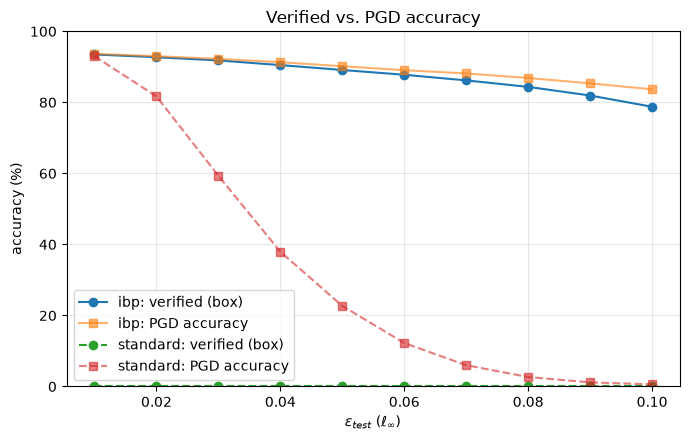

In [9]:
epsilons = [round(0.01 * k, 2) for k in range(1, 11)]   # 0.01, 0.02, ..., 0.1


@torch.no_grad()
def verified_accuracy(model, eps):
    model.eval()
    cert = 0
    for x, y in test_loader:
        cert += verify_batch(model, x.to(device), y.to(device), eps).sum().item()
    return 100 * cert / len(test_dataset)


table_b = {kind: {"verified": [], "pgd": []} for kind in models}
for eps in epsilons:
    for kind, m in models.items():
        table_b[kind]["verified"].append(verified_accuracy(m, eps))
        table_b[kind]["pgd"].append(test_accuracy(m, eps=eps))

print(f"{'eps':>6} | {'IBP verified':>12} {'IBP PGD':>8} | {'std verified':>12} {'std PGD':>8}")
for k, eps in enumerate(epsilons):
    print(f"{eps:>6.2f} | {table_b['ibp']['verified'][k]:>11.2f}% {table_b['ibp']['pgd'][k]:>7.2f}% | "
          f"{table_b['standard']['verified'][k]:>11.2f}% {table_b['standard']['pgd'][k]:>7.2f}%")

plt.figure(figsize=(7, 4.5))
for kind, style in [("ibp", "-"), ("standard", "--")]:
    plt.plot(epsilons, table_b[kind]["verified"], "o" + style, label=f"{kind}: verified (box)")
    plt.plot(epsilons, table_b[kind]["pgd"], "s" + style, alpha=0.6, label=f"{kind}: PGD accuracy")
plt.xlabel(r"$\epsilon_{test}$ ($\ell_\infty$)"); plt.ylabel("accuracy (%)"); plt.ylim(0, 100)
plt.grid(alpha=0.3); plt.legend(); plt.title("Verified vs. PGD accuracy"); plt.tight_layout(); plt.show()

### Adversarial examples where the IBP network is not certified

For each $\epsilon_{test}$, we take the test images that the IBP network classifies correctly but that the verifier does
not certify, and search for adversarial examples in their $\epsilon_{test}$-ball with a stronger PGD attack (100 steps,
5 random restarts). Each uncertified image is then either *attacked* (a real adversarial example exists) or *undecided*
(no adversarial example found, but not proven robust: this is the incompleteness of the box verifier, or a weakness of the attack).

In [10]:
@torch.no_grad()
def predict(model, x):
    return model(x).argmax(1)


ibp_model = models["ibp"].eval()
x_all = torch.stack([test_dataset[i][0] for i in range(len(test_dataset))]).to(device)
y_all = torch.tensor(test_dataset.targets).to(device) if not torch.is_tensor(test_dataset.targets) else test_dataset.targets.to(device)
correct_all = predict(ibp_model, x_all) == y_all

torch.manual_seed(0)
adv_found = {}   # eps -> (indices, adversarial images, adversarial predictions)
print(f"{'eps':>6} {'certified':>10} {'not cert. (correct)':>20} {'attacked':>9} {'undecided':>10} {'misclassified':>14}")
for eps in epsilons:
    cert = torch.cat([verify_batch(ibp_model, x_all[i:i + 1000], y_all[i:i + 1000], eps)
                      for i in range(0, len(x_all), 1000)])
    idx = torch.nonzero(correct_all & ~cert).squeeze(1)
    x_adv = torch.cat([pgd_linf(ibp_model, x_all[idx[i:i + 1000]], y_all[idx[i:i + 1000]], eps, steps=100, restarts=5)
                       for i in range(0, len(idx), 1000)]) if len(idx) else x_all[:0]
    pred_adv = predict(ibp_model, x_adv) if len(idx) else y_all[:0]
    success = pred_adv != y_all[idx]
    adv_found[eps] = (idx[success], x_adv[success], pred_adv[success])
    assert (x_adv - x_all[idx]).abs().max() <= eps + 1e-6
    print(f"{eps:>6.2f} {cert.sum().item():>10d} {len(idx):>20d} {success.sum().item():>9d} "
          f"{(~success).sum().item():>10d} {(~correct_all).sum().item():>14d}")

   eps  certified  not cert. (correct)  attacked  undecided  misclassified


  0.01       9349                   89        72         17            562


  0.02       9271                  167       140         27            562


  0.03       9181                  257       216         41            562


  0.04       9049                  389       313         76            562


  0.05       8912                  526       427         99            562


  0.06       8777                  661       542        119            562


  0.07       8619                  819       640        179            562


  0.08       8436                 1002       777        225            562


  0.09       8193                 1245       926        319            562


  0.10       7876                 1562      1104        458            562


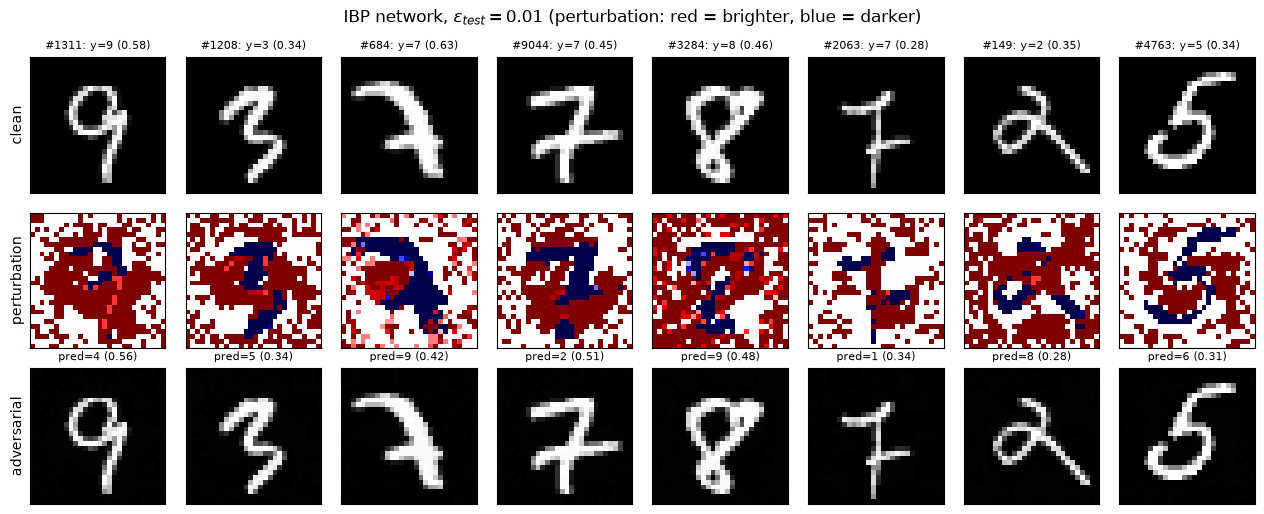

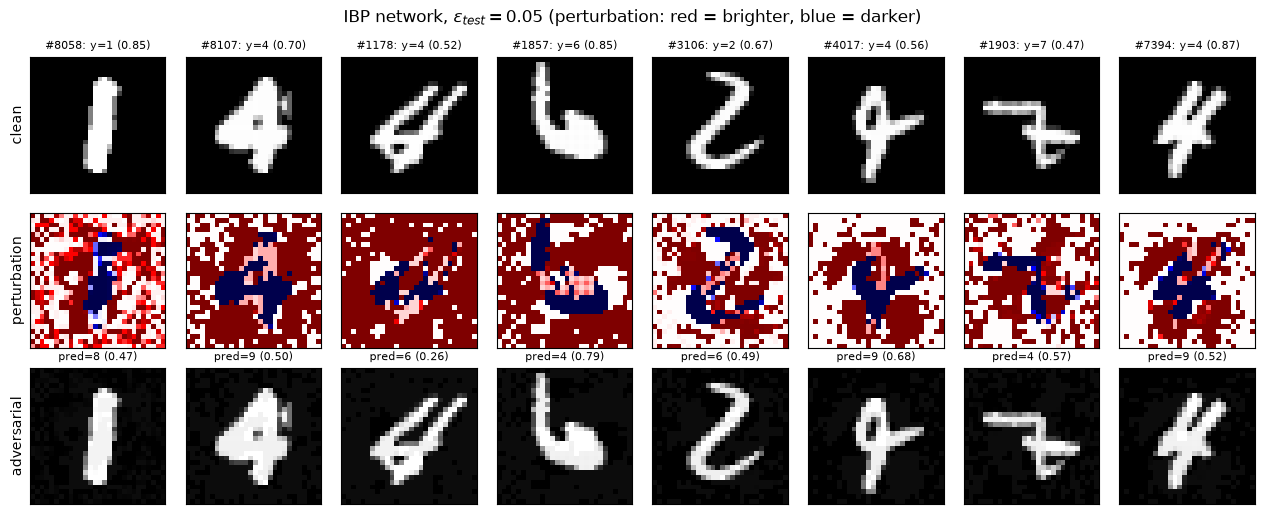

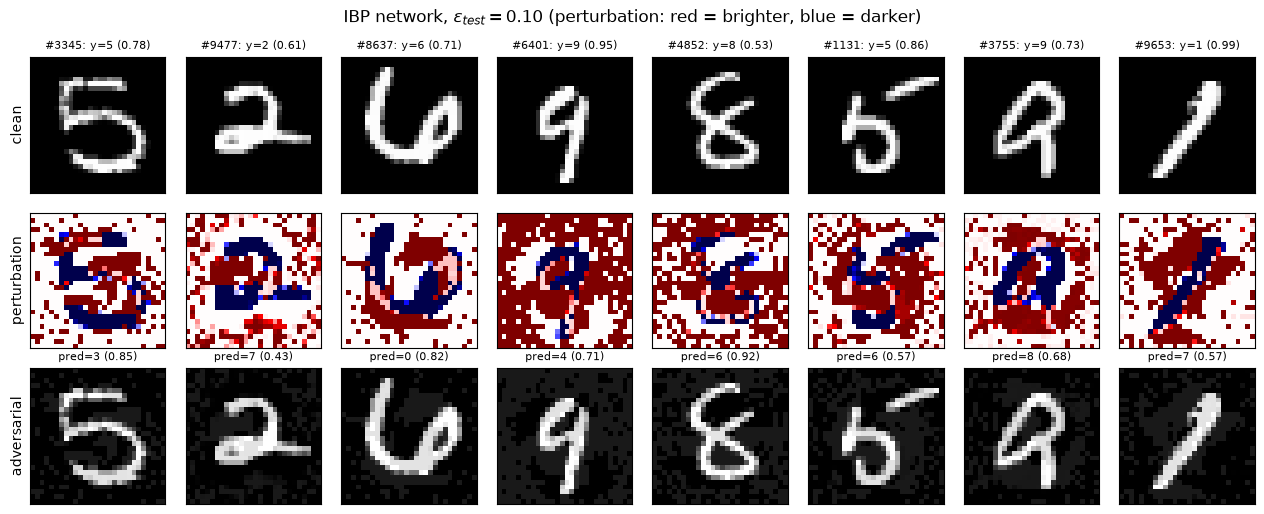

In [11]:
def show_examples(eps, k=8):
    idx, x_adv, pred = adv_found[eps]
    sel = torch.randperm(len(idx), generator=torch.Generator().manual_seed(1))[:k]
    fig, axes = plt.subplots(3, k, figsize=(1.6 * k, 5.2))
    for col, s in enumerate(sel):
        i = idx[s].item()
        clean, adv = x_all[i, 0].cpu(), x_adv[s, 0].cpu()
        p_clean = torch.softmax(ibp_model(x_all[i:i + 1]), 1)[0, y_all[i]].item()
        p_adv = torch.softmax(ibp_model(x_adv[s:s + 1]), 1)[0, pred[s]].item()
        axes[0, col].imshow(clean, cmap="gray", vmin=0, vmax=1)
        axes[0, col].set_title(f"#{i}: y={y_all[i].item()} ({p_clean:.2f})", fontsize=8)
        axes[1, col].imshow(adv - clean, cmap="seismic", vmin=-eps, vmax=eps)
        axes[2, col].imshow(adv, cmap="gray", vmin=0, vmax=1)
        axes[2, col].set_title(f"pred={pred[s].item()} ({p_adv:.2f})", fontsize=8)
    for a in axes.ravel():
        a.set_xticks([]); a.set_yticks([])
    axes[0, 0].set_ylabel("clean"); axes[1, 0].set_ylabel("perturbation"); axes[2, 0].set_ylabel("adversarial")
    fig.suptitle(rf"IBP network, $\epsilon_{{test}} = {eps:.2f}$ (perturbation: red = brighter, blue = darker)")
    plt.tight_layout(); plt.show()


eps_small = next(e for e in epsilons if len(adv_found[e][0]) >= 8)
for eps in [eps_small, 0.05, 0.1]:
    show_examples(eps)

In [12]:
from collections import Counter

# Smallest eps (on the grid) at which each test image gets an adversarial example, and the most frequent confusions.
first_eps = {}
for eps in epsilons:
    for i, p in zip(adv_found[eps][0].tolist(), adv_found[eps][2].tolist()):
        first_eps.setdefault(i, (eps, p))

conf = Counter((y_all[i].item(), p) for i, (e, p) in first_eps.items())
print("most frequent (true -> adversarial) confusions:", conf.most_common(10))
by_digit = Counter(y_all[i].item() for i in first_eps)
n_digit = Counter(y_all.tolist())
print("fraction of test images of each digit that get an adversarial example at eps <= 0.1:")
print({d: round(by_digit[d] / n_digit[d], 3) for d in range(10)})

idx, x_adv, _ = adv_found[0.1]
delta = (x_adv - x_all[idx]).flatten(1)
print(f"\neps = 0.1: mean |delta| = {delta.abs().mean():.4f}, "
      f"fraction of pixels at +-eps = {(delta.abs() > 0.099).float().mean():.3f}, "
      f"fraction of pixels unchanged = {(delta.abs() < 1e-6).float().mean():.3f}")

most frequent (true -> adversarial) confusions: [((5, 3), 76), ((4, 9), 62), ((2, 8), 55), ((5, 8), 49), ((3, 5), 48), ((9, 4), 44), ((1, 8), 35), ((8, 5), 31), ((7, 2), 29), ((3, 8), 28)]
fraction of test images of each digit that get an adversarial example at eps <= 0.1:
{0: 0.046, 1: 0.042, 2: 0.143, 3: 0.135, 4: 0.109, 5: 0.217, 6: 0.118, 7: 0.095, 8: 0.133, 9: 0.099}

eps = 0.1: mean |delta| = 0.0557, fraction of pixels at +-eps = 0.493, fraction of pixels unchanged = 0.359


### Results and analysis of (b)

| $\epsilon_{test}$ | 0.01 | 0.02 | 0.03 | 0.04 | 0.05 | 0.06 | 0.07 | 0.08 | 0.09 | 0.10 |
|---|---|---|---|---|---|---|---|---|---|---|
| IBP network: verified accuracy (%) | 93.49 | 92.71 | 91.81 | 90.49 | 89.12 | 87.77 | 86.19 | 84.36 | 81.93 | 78.76 |
| IBP network: PGD accuracy (%) | 93.66 | 93.00 | 92.24 | 91.32 | 90.17 | 89.06 | 88.14 | 86.87 | 85.35 | 83.67 |
| standard network: verified accuracy (%) | 0.00 | 0.00 | 0.00 | 0.00 | 0.00 | 0.00 | 0.00 | 0.00 | 0.00 | 0.00 |
| standard network: PGD accuracy (%) | 93.00 | 81.68 | 59.33 | 37.94 | 22.68 | 12.23 | 6.00 | 2.66 | 1.16 | 0.61 |

**Verified accuracy.** The box verifier certifies 78.8% of the test set for the IBP network at $\epsilon_{test} = 0.1$
and 93.5% at $\epsilon_{test} = 0.01$. It certifies nothing for the standard network, even at $\epsilon_{test} = 0.01$:
without IBP training, the intervals grow with every layer (the $|W| r$ term) and become too wide, even though PGD only
breaks 1.6% of the correct images at 0.01. IBP training makes the network *verifiable by the box domain*: the weights
learn to keep the intervals small. The gap between the PGD accuracy and the verified accuracy of the IBP network is small
(0.2 points at 0.01, 4.9 points at 0.1). The true robust accuracy is between the two curves.

**Where the network is not certified.** Of the 9,438 correctly classified test images, the stronger attack (100 steps, 5
restarts) finds a real adversarial example for most of the uncertified images: 72 of 89 at $\epsilon_{test} = 0.01$ and
1,104 of 1,562 at 0.1. For these images, the network is really not robust, so no verifier could certify them. The remaining
17 (at 0.01) to 458 (at 0.1) images are *undecided*. They are either robust but not provable with boxes (the box domain
ignores the dependence between neurons, so it is incomplete), or robust only against our attack. The number of undecided images grows
with $\epsilon$, because the box over-approximation grows with the size of the input region.

**The adversarial examples** (figures above):

* *Small $\epsilon$ (0.01).* The attacked images are the ambiguous ones: the network gives the true class only
  0.28–0.63 probability on the clean image (an open 9 that looks like a 4, a 7 with a bar that looks like a 2, a thin 7
  that looks like a 1). These images are already close to a decision boundary, so a perturbation of 2.5 gray levels is enough.
* *Large $\epsilon$ (0.1).* The attack also breaks images that the network classifies with high confidence (for example
  0.95 for a 9 and 0.99 for a 1). To a human, all the adversarial images are still clearly the true digit. The perturbation
  adds a gray haze to the background and dims the strokes in selected places. It is a structured pattern: it brightens
  pixels where the target digit would have a stroke (for example it closes the top of a 4-like 9 and turns a 5 into a 3 by
  brightening the region where a 3 has its upper-left curve). At $\epsilon = 0.1$, 49% of the pixels are at $\pm\epsilon$,
  as expected from the sign steps of $\ell_\infty$ PGD, and 36% are unchanged. These are mostly background pixels that the attack wants to darken,
  but they are already 0 and the $[0,1]$ clamp stops them.
* *Confusions.* The most frequent (true → adversarial) pairs are 5→3, 4→9, 2→8, 5→8, 3→5 and 9→4. These are pairs of digits
  that differ by a few strokes, so a bounded perturbation can add or remove the difference. The digits 5, 2, 3 and 8
  are the least robust (14–22% of them get an adversarial example at some $\epsilon \le 0.1$), and the simple shapes 0 and
  1 are the most robust (4–5%).